**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/19_verifying_flaky_test_fixes.ipynb)** | **🔵 [R](../r/19_verifying_flaky_test_fixes.ipynb)** | **⬅️ [Prev: Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)** | **➡️ [Next: Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)**

*🧭 Part V: Production Reliability, CI/CD & Active Learning — Chapter 19 of 22*

---

# Chapter 19: Verifying Flaky Test Fixes — Frequentist vs. Bayesian Approaches
### *Why 0/100 Passes Proves Almost Nothing, and How Wald's SPRT, Bayes Factors, and Sequential Stopping Solve CI Flakiness*

---


> 📖 **Conceptual Companion**: The 50-sided die, the courtroom shoe print ($BF=4.0$), and the hydraulic shake table:  
> Read **[Chapter 19: The 50-Sided Die & Sequential Stopping](../conceptual/19_verifying_flaky_test_fixes.ipynb)**.


---

## 1. Problem Framing: The Software Engineering Dilemma

Every software engineer, DevOps engineer, and engineering manager has lived through this exact scenario:

```
Step 1: In CI, an automated integration test begins failing intermittently.
        Across the last 100 runs on main, it failed twice:
        Pre-fix failure rate: 2 failures / 100 runs = 2.0%

Step 2: An engineer investigates, spots a likely race condition or network timeout,
        writes a patch, and opens a Pull Request.

Step 3: To "prove" the fix works, they loop the test 100 times locally or in CI:
        for i in {1..100}; do pytest tests/test_payment.py; done

Step 4: All 100 runs pass without a single failure (0/100)!

Step 5: The engineer posts a PR comment: "Fixed! Passed 100/100 runs without error."
        The PR is approved and merged to main...
        ...and 48 hours later, the exact same test flakes during a production deployment!
```

---

### 🎲 The Everyday Intuition: The 50-Sided Die

Why does this happen so frequently? Let us translate this scenario into an everyday physical game:

> [!IMPORTANT]
> **The 50-Sided Die (The Loaded Die Mental Model)**
> 
> Imagine someone hands you a **50-sided die** where exactly **one face** is painted bright red (representing the 2% failure rate).
> 
> * If you roll this die **100 times**, what is the probability that the red face **never shows up at all**?
> * Each roll has a $49/50 = 98\%$ chance of landing safe.
> * The probability of rolling 100 safe faces in a row is:
>   $$P(0 \text{ red in } 100) = (0.98)^{100} \approx 0.1326 \quad (13.3\%)$$
> 
> **Think about what 13.3% means in everyday life:**
> * When you roll a standard **6-sided board game die**, your chance of rolling a **6** on a single roll is $1/6 \approx 16.7\%$.
> * A $13.3\%$ probability is roughly **1 out of every 7.5 times**!
> * If you roll a 6 on a single die roll, do you declare that the die is broken and can never roll anything else? Of course not!
> * Yet software engineers celebrate 100 consecutive passes as "irrefutable proof" that a bug is permanently dead, when they have merely observed an outcome **almost as common as rolling a 6 on a board game die**!

---

### 🧠 The Human Intuition Trap: The Illusion of "100"

Why do smart engineers consistently fall for this trap?
* **The Cognitive Bias**: Human intuition evolved to count visible physical objects—people in a tribe, livestock, apples in a basket. To our brains, the number **100** feels enormous, exhaustive, and conclusive.
* **The Statistical Reality**: In probability theory, **sample size has no absolute meaning in isolation**. Sample size only has meaning **relative to the rarity of the event** you are trying to detect!
  * If a machine fails once every 10 runs ($p = 10\%$), 100 runs is plenty of evidence.
  * If a satellite fails once every 1,000,000 hours, observing it for 100 hours proves literally nothing.
  * For a test that flakes $2\%$ of the time, 100 runs is a tiny, noisy peephole!

---

### 🗺️ What This Guide Teaches You

This notebook deconstructs this problem through both foundational statistical lenses and provides practical production solutions:

| Statistical Question | Frequentist Lens (Sections 2.1 – 2.4) | Bayesian Lens (Sections 3.1 – 3.3) | Practical CI Production Solution |
| :--- | :--- | :--- | :--- |
| **Did the test actually improve?** | **Fisher's Exact Test**: $p = 0.25$ (Fails significance test; no evidence of cure). | **Bayes Factor**: $BF_{10} = 4.0$ (Weak circumstantial evidence; suspect shoe print). | Do not promote or merge on 100 clean runs alone. |
| **What is the guaranteed failure rate?** | **Rule of Three**: True flakiness is upper-bounded by $\le 3.0\%$ (worse than pre-fix!). | **Beta Posterior**: Full credible interval $[0.0\%, 2.9\%]$; accounts for uncertainty. | If using fixed batches, compute $N \ge 3 / p_{\text{tolerance}}$ ($300\text{--}600$ runs). |
| **How do we avoid wasting CI compute?** | **Wald's SPRT**: Dynamic sequential stopping stops early on failures or proven health. | **Posterior Updating**: Online belief updating after every individual run. | Abort immediately on the first failure post-fix; don't finish all 100 runs. |
| **How do we incorporate PR fix quality?** | ❌ Cannot incorporate prior developer context (pure data only). | ✅ **Prior Odds**: Weights evidence by whether the PR is a sleep bump ($35\%$) or root cause ($95\%$). | Use Bayesian decision gates based on change risk archetype. |
| **When is it economically optimal to stop?** | Arbitrary $\alpha$ and $\beta$ thresholds. | **Bayesian Decision Theory**: Balances &#36;0.01 runner cost vs. &#36;500 broken-build cost. | Stop when the cost of testing exceeds the expected risk of failure. |


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.special import betaln, comb

# Matplotlib formatting for crisp, readable plots
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16
})

print("Scientific libraries loaded successfully.")

Scientific libraries loaded successfully.


---

## 2. The Frequentist Deconstruction

Let us begin by applying classical frequentist hypothesis testing to the engineer's experiment.

### 2.1 The Two-Proportion Test & Fisher's Exact Test

In the frequentist framework, we set up two competing hypotheses about the true pre-fix failure probability $p_{\text{pre}}$ and the post-fix failure probability $p_{\text{post}}$:
$$H_0: p_{\text{post}} = p_{\text{pre}} \quad (\text{Null Hypothesis: The patch had zero effect})$$
$$H_1: p_{\text{post}} < p_{\text{pre}} \quad (\text{Alternative Hypothesis: The patch reduced flakiness})$$

Our empirical observations form a classic $2 \times 2$ contingency table:

| Test Phase | Failures ($k$) | Passes ($n - k$) | Total Runs ($n$) | Empirical Failure Rate ($\hat{p}$) |
| :--- | :---: | :---: | :---: | :---: |
| **Pre-Fix (Main Branch)** | 2 | 98 | 100 | 2.0% |
| **Post-Fix (PR Branch)** | 0 | 100 | 100 | 0.0% |
| **Total** | **2** | **198** | **200** | **1.0%** |

---

> [!TIP]
> ### 💊 The Clinical Trial Analogy (The Sugar Pill)
> 
> Imagine a pharmaceutical company testing a new anti-migraine pill against a sugar pill (placebo):
> * **Placebo Group (100 patients)**: 2 patients still suffer migraines ($2\%$).
> * **New Drug Group (100 patients)**: 0 patients suffer migraines ($0\%$).
> 
> The company CEO says: *"Look, 0% vs 2%! The new drug completely cured migraines!"*
> 
> Fisher's Exact Test asks the critical skeptical question:
> > *"Suppose the drug is literally identical to the sugar pill (100% ineffective). Across all 200 patients, exactly 2 people happened to have a migraine. What are the odds that purely by the luck of the draw, both of those 2 sick people happened to be placed in the placebo group?"*

---

> [!NOTE]
> ### 🎱 The Marble Urn Mental Model
> 
> Picture a large urn with **200 marbles**:
> * **2 red marbles** (failures)
> * **198 green marbles** (passes)
> 
> You reach into the urn blindfolded, pull out **100 marbles** for the "Pre-Fix" pile, and leave the other **100 marbles** for the "Post-Fix" pile.
> 
> What is the exact mathematical probability that **both red marbles** ended up in the first pile purely by random chance?
> 
> We compute this using the hypergeometric distribution:
> $$P(\text{Both Red in First Pile} \mid H_0) = \frac{\binom{2}{2} \binom{198}{98}}{\binom{200}{100}} = \frac{\binom{2}{0} \binom{198}{100}}{\binom{200}{100}} = \frac{100 \times 99}{200 \times 199} = \frac{9{,}900}{39{,}800} \approx \mathbf{0.2487} \quad (24.87\%)$$


In [2]:
# 2x2 contingency table: [[Pre-Fail, Pre-Pass], [Post-Fail, Post-Pass]]
contingency_table = [[2, 98], [0, 100]]

# One-sided Fisher's Exact Test: alternative='greater' tests if pre odds > post odds (i.e. post rate < pre rate)
odds_ratio, p_value_one_sided = stats.fisher_exact(contingency_table, alternative='greater')
_, p_value_two_sided = stats.fisher_exact(contingency_table, alternative='two-sided')

print("=" * 65)
print("FREQUENTIST HYPOTHESIS TEST: 2/100 (Pre) vs. 0/100 (Post)")
print("=" * 65)
print(f"One-sided p-value (H_1: p_post < p_pre): {p_value_one_sided:.4f} ({p_value_one_sided:.1%})")
print(f"Two-sided p-value (H_1: p_post != p_pre): {p_value_two_sided:.4f} ({p_value_two_sided:.1%})")
print(f"Statistically significant at alpha = 0.05? {p_value_one_sided < 0.05}")
print("=" * 65)

FREQUENTIST HYPOTHESIS TEST: 2/100 (Pre) vs. 0/100 (Post)
One-sided p-value (H_1: p_post < p_pre): 0.2487 (24.9%)
Two-sided p-value (H_1: p_post != p_pre): 0.4975 (49.7%)
Statistically significant at alpha = 0.05? False


---

> [!WARNING]
> ### ⚖️ The Frequentist Verdict: Inconclusive ($p \approx 0.25$)
> Under standard scientific criteria ($\alpha = 0.05$):
> 
> $$\mathbf{p = 0.2487 \gg 0.05}$$
> 
> **We completely fail to reject the null hypothesis.**
> 
> In plain English:
> * There is an almost **25% chance** (1 out of every 4 times!) of observing this exact improvement purely by random sampling noise, even if the patch did **absolutely nothing**!
> * If the FDA was reviewing a drug whose trial had a $p$-value of $0.25$, they would immediately throw the application in the trash.
> * Yet software engineers routinely merge code into production on this exact same statistical evidence.

---

### 2.2 The Zero-Failure Sampling Probability: $(1 - p)^N$

Why is the $p$-value so high? Because when an underlying event has a low base rate ($p = 0.02$, or 2%), observing zero occurrences in a small sample of size $N = 100$ is completely routine:

$$P(K = 0 \mid N = 100, p = 0.02) = (1 - 0.02)^{100} = 0.98^{100} \approx 0.1326 \quad (13.26\%)$$

> [!NOTE]
> ### ⚾ The "Cold Streak" Sports Analogy
> Consider a professional baseball player with a career batting average of $.200$ (they get a hit 1 out of 5 times, failing 80% of the time).
> * What are the odds this player has a slump and goes **0-for-10** at the plate?
>   $$P(0 \text{ hits in } 10) = (0.80)^{10} \approx 0.107 \quad (10.7\%)$$
> * Does an 0-for-10 slump mean the player has forgotten how to swing a bat and will never get a hit again? No! It is a routine cold streak that happens multiple times every season.
> * Similarly, when an automated test has a $2\%$ failure rate, a streak of 100 clean passes is simply a routine "cold streak" for failures—not proof that the failure mechanism has been eradicated.


### 2.3 The Rule of Three & Upper Confidence Bounds

When you run a test $N$ times and observe **zero failures** ($k = 0$), what is the frequentist 95% confidence upper bound on the true failure rate $p$?

Most engineers instinctively think: *"I saw 0 failures in 100 runs, so the failure rate is 0%!"*
Statistically, this is false. 0/100 only tells you that the failure rate is likely below some upper bound. But what is that bound?

Under exact Clopper-Pearson binomial confidence intervals:
$$(1 - p_{\text{upper}})^N = 0.05 \implies N \ln(1 - p_{\text{upper}}) = \ln(0.05)$$

Using the first-order Taylor series approximation $\ln(1 - x) \approx -x$ for small $x$:
$$-N \cdot p_{\text{upper}} \approx \ln(0.05) \approx -2.9957 \implies \mathbf{p_{\text{upper}} \approx \frac{3}{N}}$$

This is the celebrated **Rule of Three** (Hanley & Lippman-Hand, 1983; Jovanovic & Levy, 1997).

---

> [!TIP]
> ### 🎯 Where Does the "3" Come From? (The "Three Strikes" Intuition)
> 
> You might wonder: why does the number 3 appear in this formula? Where does 3 come from physically?
> 
> * If a test has true failure rate $p$, the expected number of failures in $N$ runs is $\mu = N \cdot p$.
> * Under a Poisson approximation, the probability of observing zero occurrences when you expect $\mu$ is $P(K=0) = e^{-\mu}$.
> * Let us calculate how surprising "zero occurrences" is for different expected values:
>   * If you expect $\mu = 1$ failure: $P(K=0) = e^{-1} \approx 36.8\%$ (very common!).
>   * If you expect $\mu = 2$ failures: $P(K=0) = e^{-2} \approx 13.5\%$ (still quite common!).
>   * If you expect $\mu = 3$ failures: $P(K=0) = e^{-3} \approx 0.0498 \approx \mathbf{5.0\%}$!
> 
> **The Intuitive Punchline**:
> Seeing zero failures only becomes statistically surprising (dropping below the $5\%$ error threshold) once you have observed enough runs that **you would have expected to see at least 3 failures**!
> 
> Therefore:
> $$\text{Expected Failures} = N \cdot p_{\text{upper}} \ge 3 \implies p_{\text{upper}} \approx \frac{3}{N}$$

---

> [!WARNING]
> ### 🛑 The Paradox of the Rule of Three: You Proved Nothing!
> 
> Let us evaluate what happens after the engineer runs their 100 tests with 0 failures:
> $$p_{\text{upper}} \approx \frac{3}{100} = 0.03 \quad (3.0\%)$$
> 
> Look carefully at the numbers:
> * **Before the fix**: The test was flaking at **2.0%** ($2/100$).
> * **After 100 clean passes**: Your frequentist 95% confidence upper bound is **3.0%**!
> 
> **You have not proved the test is fixed. You have not even proved it is better than before!**
> With 95% confidence, the true flakiness could easily be $2.8\%$, which is *worse* than the rate that triggered the bug report in the first place!


In [3]:
# Exact Clopper-Pearson 95% Upper Bound for k=0 failures in N runs
def clopper_pearson_upper_bound(n, alpha=0.05):
    # For k=0, exact bound is 1 - alpha**(1/n)
    return 1.0 - alpha**(1.0 / n)

sample_sizes = [50, 100, 200, 300, 600, 1000]
print("EXACT 95% UPPER BOUND ON FLAKINESS AFTER 0 FAILURES:")
print("-" * 55)
for n in sample_sizes:
    exact_ub = clopper_pearson_upper_bound(n, alpha=0.05)
    approx_ub = 3.0 / n
    print(f"N = {n:4d} runs | Exact Bound: {exact_ub:.2%} | Rule of Three: {approx_ub:.2%}")
print("-" * 55)

EXACT 95% UPPER BOUND ON FLAKINESS AFTER 0 FAILURES:
-------------------------------------------------------
N =   50 runs | Exact Bound: 5.82% | Rule of Three: 6.00%
N =  100 runs | Exact Bound: 2.95% | Rule of Three: 3.00%
N =  200 runs | Exact Bound: 1.49% | Rule of Three: 1.50%
N =  300 runs | Exact Bound: 0.99% | Rule of Three: 1.00%
N =  600 runs | Exact Bound: 0.50% | Rule of Three: 0.50%
N = 1000 runs | Exact Bound: 0.30% | Rule of Three: 0.30%
-------------------------------------------------------


---

### 2.4 The Frequentist Solution: Wald's Sequential Probability Ratio Test (SPRT)

If fixed batches of $N = 100$ are inadequate, what is the alternative? Running a fixed batch of $N = 600$ every time an engineer opens a PR is far too slow and expensive for modern CI/CD.

This exposes the fundamental architectural flaw of fixed-sample testing:
1. **If the fix FAILED** (e.g., the bug is still present or made worse, $p = 10\%$): Waiting for 100 or 600 runs wastes immense cloud compute when the test fails on run #4.
2. **If the fix SUCCEEDED** (the test is clean, $p < 0.1\%$): We want to stop testing and approve the PR the moment we reach statistical certainty, not an arbitrary run count.

---

> [!TIP]
> ### 🏎️ The Speed Camera vs. The 100-Lap Track Test
> 
> Imagine a mechanic tests whether a car's braking system has a defect:
> * **Fixed-Sample Testing ($N=100$)**: The mechanic insists: *"We must drive exactly 100 laps around the track before we make any diagnosis."* Even if the brakes fail on lap 3, they keep driving for 97 more laps!
> * **Sequential Testing (Wald's SPRT)**: The mechanic has an onboard sensor. If the brake fails on lap 3, they pull over immediately and say: *"Brakes are defective; test aborted."* If the brakes perform flawlessly for 150 laps, the sensor signals that the risk threshold has been cleared and stops the test early.

---

### Abraham Wald's SPRT: Online Dynamic Stopping

Developed by Abraham Wald during World War II for quality control of military munitions, the **Sequential Probability Ratio Test (SPRT)** evaluates incoming test results **one run at a time** ($m = 1, 2, 3, \dots$):

* $H_0$ (Clean / Fixed): Failure probability is below acceptable baseline ($p \le p_0$, e.g. $p_0 = 0.001$, or $0.1\%$).
* $H_1$ (Flaky / Broken): Failure probability is at or above flaky rate ($p \ge p_1$, e.g. $p_1 = 0.02$, or $2.0\%$).
* $\alpha = 0.05$: False alarm tolerance (declaring a good test flaky).
* $\beta = 0.05$: Missed detection tolerance (declaring a flaky test clean; 95% statistical power).

The stopping boundaries are:
$$A = \ln\left(\frac{1 - \beta}{\alpha}\right) = \ln(19) \approx +2.944 \quad (\text{Upper Boundary: Reject } H_0 \text{ / Flaky})$$
$$B = \ln\left(\frac{\beta}{1 - \alpha}\right) = \ln\left(\frac{1}{19}\right) \approx -2.944 \quad (\text{Lower Boundary: Accept } H_0 \text{ / Clean})$$

The cumulative log-likelihood score after $m$ runs with $k$ failures is:
$$S_m = k \cdot \ln\left(\frac{p_1}{p_0}\right) + (m - k) \cdot \ln\left(\frac{1 - p_1}{1 - p_0}\right)$$

---

> [!NOTE]
> ### ⚖️ The Balance Scale (Grains of Sand vs. Sledgehammer)
> 
> Picture a balance scale starting at balance ($S_0 = 0$):
> * **Each Pass**: Adds a tiny downward nudge toward the clean boundary $B = -2.944$:
>   $$\Delta S_{\text{pass}} = \ln\left(\frac{1 - 0.02}{1 - 0.001}\right) = \ln\left(\frac{0.98}{0.999}\right) \approx \mathbf{-0.0192} \text{ points}$$
>   It takes $\frac{-2.944}{-0.0192} \approx \mathbf{154 \text{ consecutive passes}}$ (grains of sand) to tip the scale down into the Clean zone.
> 
> * **Each Failure**: Drops a **giant sledgehammer** toward the flaky boundary $A = +2.944$:
>   $$\Delta S_{\text{fail}} = \ln\left(\frac{0.02}{0.001}\right) = \ln(20) \approx \mathbf{+2.996} \text{ points}$$
>   **A SINGLE failure instantly slams the score from 0 past the upper threshold (+2.944) into instant rejection!**


In [4]:
class SequentialProbabilityRatioTest:
    def __init__(self, p0=0.001, p1=0.02, alpha=0.05, beta=0.05):
        self.p0 = p0
        self.p1 = p1
        self.alpha = alpha
        self.beta = beta
        
        # Stopping thresholds
        self.A = np.log((1 - beta) / alpha)
        self.B = np.log(beta / (1 - alpha))
        
        # Log-likelihood increments
        self.ll_fail = np.log(p1 / p0)
        self.ll_pass = np.log((1 - p1) / (1 - p0))
        
        self.reset()

    def reset(self):
        self.m = 0
        self.k = 0
        self.S_m = 0.0
        self.history = [0.0]
        self.status = "CONTINUE"

    def step(self, failed: bool):
        self.m += 1
        if failed:
            self.k += 1
            self.S_m += self.ll_fail
        else:
            self.S_m += self.ll_pass
            
        self.history.append(self.S_m)
        
        if self.S_m <= self.B:
            self.status = "ACCEPT_H0 (CLEAN)"
        elif self.S_m >= self.A:
            self.status = "REJECT_H0 (FLAKY)"
        else:
            self.status = "CONTINUE"
            
        return self.status

sprt = SequentialProbabilityRatioTest(p0=0.001, p1=0.02, alpha=0.05, beta=0.05)
# Calculate runs needed if all pass:
runs_needed_clean = int(np.ceil(sprt.B / sprt.ll_pass))
print(f"SPRT Upper Bound A (Flaky): {sprt.A:+.3f}")
print(f"SPRT Lower Bound B (Clean): {sprt.B:+.3f}")
print(f"Single failure log-weight:  {sprt.ll_fail:+.3f}")
print(f"Single pass log-weight:     {sprt.ll_pass:+.3f}")
print(f"Consecutive clean passes required to prove fix: {runs_needed_clean} runs")

SPRT Upper Bound A (Flaky): +2.944
SPRT Lower Bound B (Clean): -2.944
Single failure log-weight:  +2.996
Single pass log-weight:     -0.019
Consecutive clean passes required to prove fix: 154 runs


---

## 3. The Bayesian Deconstruction

Now let us step into the Bayesian framework. Rather than asking *"Did this patch reject the null hypothesis?"*, the Bayesian engineer asks:
> *"Given our prior knowledge about this bug and this patch, what is our posterior probability that the test is truly fixed, and what is our remaining risk?"*

---

### 3.1 Pre-Fix Uncertainty: The $\text{Beta}(3, 99)$ Posterior

When the test failed 2 times out of 100 runs on `main`, what did we actually learn about the failure rate $\theta$?

Under an objective uninformative prior $\theta \sim \text{Beta}(1, 1)$, our posterior distribution using conjugate updating is:
$$\theta_{\text{pre}} \sim \text{Beta}(1 + 2, 1 + 98) = \text{Beta}(3, 99)$$

```
Expected Value (Mean):   E[theta] = 3 / 102 ≈ 2.94%
Most Likely Value (Mode): Mode(theta) = 2 / 100 = 2.00%
95% Credible Interval:   [0.61%, 7.08%]
```

> [!NOTE]
> ### 🔦 The Flashlight in the Fog
> A frequentist point estimate of $\hat{p} = 2.0\%$ provides a dangerous illusion of precision.
> In reality, 2 failures in 100 runs is like shining a weak flashlight through dense fog:
> * The test might be very mildly flaky ($0.6\%$, or 1 failure every 165 runs).
> * Or it might be severely broken ($7.1\%$, or 1 failure every 14 runs)!
> 
> The Bayesian distribution $\text{Beta}(3, 99)$ preserves this honest uncertainty rather than collapsing it into a false point estimate.

---

### 3.2 The Bayes Factor of 100 Clean Passes

Now the developer runs 100 tests post-fix and observes **zero failures** ($k = 0, n = 100$).
We set up a formal Bayesian model comparison between two hypotheses:
* **$M_1$ (Fix Succeeded)**: The root cause was eliminated; the test has returned to a clean baseline: $\theta \sim \text{Beta}(1, 100)$ (mean $\approx 1\%$, mode $= 0\%$).
* **$M_0$ (Fix Ineffective / Placebo)**: The patch did not touch the root cause; flakiness remains in its pre-fix state: $\theta \sim \text{Beta}(3, 99)$.

Using the **Beta-Binomial marginal likelihood** (integrating out parameter uncertainty across all possible values of $\theta$):

$$P(k = 0, n = 100 \mid M_0) = \frac{\text{B}(3+0, \, 99+100)}{\text{B}(3, 99)} = \frac{101 \times 100 \times 99}{201 \times 200 \times 199} \approx 0.1250 \quad (12.50\%)$$

$$P(k = 0, n = 100 \mid M_1) = \frac{\text{B}(1+0, \, 100+100)}{\text{B}(1, 100)} = \frac{100}{200} = 0.5000 \quad (50.00\%)$$

The **Bayes Factor ($BF_{10}$)** is the ratio of how much more likely the data is under the "Fixed" model than under the "Still Broken" model:
$$BF_{10} = \frac{P(D \mid M_1)}{P(D \mid M_0)} = \frac{0.5000}{0.12498} \approx \mathbf{4.00}$$

---

> [!IMPORTANT]
> ### 🔍 The Courtroom Footprint Analogy: What Does BF = 4.0 Mean?
> 
> In a courtroom trial, a prosecutor presents a piece of physical evidence:
> > *"A size-10 boot footprint was discovered outside the broken window. The defendant wears size 10 boots!"*
> 
> * If the defendant is guilty, he would certainly leave size-10 footprints ($100\%$).
> * But in the general population, roughly **25% of adult men wear size 10 boots**.
> * The Bayes Factor of the footprint evidence is:
>   $$BF = \frac{1.00}{0.25} = 4.0$$
> 
> **Would any rational jury convict a person of burglary based solely on a size-10 shoe print?**
> Absolutely not! A Bayes Factor of 4.0 is mild circumstantial evidence. It makes guilt *somewhat* more plausible, but it is nowhere near proof beyond reasonable doubt.
> 
> **100 clean passes in CI is the software engineering equivalent of that size-10 shoe print!**
> It is 4 times more likely if the bug is fixed than if it is broken, but it is far from an open-and-shut case.


In [5]:
# Analytical marginal likelihoods under Beta-Binomial
def beta_bin_lpmf(k, n, a, b):
    return np.log(comb(n, k)) + betaln(k + a, n - k + b) - betaln(a, b)

log_lik_M0 = beta_bin_lpmf(k=0, n=100, a=3, b=99)
log_lik_M1 = beta_bin_lpmf(k=0, n=100, a=1, b=100)

lik_M0 = np.exp(log_lik_M0)
lik_M1 = np.exp(log_lik_M1)
bayes_factor = lik_M1 / lik_M0

print("=" * 65)
print("BAYESIAN MODEL COMPARISON: 100 PASSES POST-FIX")
print("=" * 65)
print(f"P(100 passes | M0: Fix Failed)   = {lik_M0:.4f} ({lik_M0:.1%})")
print(f"P(100 passes | M1: Fix Worked)   = {lik_M1:.4f} ({lik_M1:.1%})")
print(f"Bayes Factor (BF_10)             = {bayes_factor:.2f}")
print("=" * 65)

# Jeffreys scale interpretation
print("Harold Jeffreys Evidence Scale:")
print("  BF 1 - 3:   Anecdotal / Barely worth mentioning")
print("  BF 3 - 10:  Substantial / Moderate (CURRENT: 4.00)")
print("  BF 10 - 30: Strong")
print("  BF > 100:   Decisive")
print("=" * 65)

BAYESIAN MODEL COMPARISON: 100 PASSES POST-FIX
P(100 passes | M0: Fix Failed)   = 0.1250 (12.5%)
P(100 passes | M1: Fix Worked)   = 0.5000 (50.0%)
Bayes Factor (BF_10)             = 4.00
Harold Jeffreys Evidence Scale:
  BF 1 - 3:   Anecdotal / Barely worth mentioning
  BF 3 - 10:  Substantial / Moderate (CURRENT: 4.00)
  BF 10 - 30: Strong
  BF > 100:   Decisive


### 3.3 Prior Fix Efficacy: Not All PRs Are Created Equal

Frequentist statistics suffers from **structural amnesia**: it forces every PR to be evaluated as an identical black box, completely ignoring engineering context.

In real-world software engineering, **who wrote the PR and what code changed matters immensely**:

$$\text{Posterior Odds} = BF_{10} \times \text{Prior Odds} \implies P(M_1 \mid D) = \frac{\text{Odds}}{1 + \text{Odds}}$$

Let us compare three common engineering archetypes:
1. **The Heuristic Patch ($P(M_1) = 35\%$)**: The developer simply bumped `time.sleep(1)` to `time.sleep(2)`. We all know that arbitrary timeout increases rarely solve underlying race conditions.
2. **The Standard Team PR ($P(M_1) = 70\%$)**: Telemetry shows that roughly 7 out of 10 PRs intended to fix flaky tests successfully resolve them on the team's repository.
3. **The Root-Cause Code Fix ($P(M_1) = 95\%$)**: The developer produced a deterministic unit reproduction, discovered an unprotected shared dictionary in a thread pool, added a mutex lock, and proved the fix mathematically.


In [6]:
priors = [0.35, 0.70, 0.95]
labels = ["Heuristic ('Bumped Sleep')", "Standard Team PR", "Root-Cause Code Fix"]

print("IMPACT OF PRIOR FIX QUALITY AFTER 100 CLEAN PASSES (BF = 4.00):")
print("-" * 75)
print(f"{'PR Fix Archetype':<26} | {'Prior P(Fix)':<12} | {'Post P(Fix)':<12} | {'Residual Flake Risk'}")
print("-" * 75)

for label, p_prior in zip(labels, priors):
    prior_odds = p_prior / (1.0 - p_prior)
    post_odds = bayes_factor * prior_odds
    p_post = post_odds / (1.0 + post_odds)
    residual_risk = 1.0 - p_post
    print(f"{label:<26} | {p_prior:<12.1%} | {p_post:<12.1%} | {residual_risk:.1%}")
print("-" * 75)

IMPACT OF PRIOR FIX QUALITY AFTER 100 CLEAN PASSES (BF = 4.00):
---------------------------------------------------------------------------
PR Fix Archetype           | Prior P(Fix) | Post P(Fix)  | Residual Flake Risk
---------------------------------------------------------------------------
Heuristic ('Bumped Sleep') | 35.0%        | 68.3%        | 31.7%
Standard Team PR           | 70.0%        | 90.3%        | 9.7%
Root-Cause Code Fix        | 95.0%        | 98.7%        | 1.3%
---------------------------------------------------------------------------


---

> [!IMPORTANT]
> ### 🏺 The Key Bayesian Insight: The Asymmetry of Evidence (The Porcelain Vase)
> 
> Why does verifying flaky tests feel like an uphill battle? Because **evidence is fundamentally asymmetric**:
> 
> * **Building Trust is Slow (Carrying the Porcelain Vase)**:
>   To prove a test is clean, you must carry a fragile vase across 150 consecutive steps without dropping it.
>   If your prior confidence in a PR was $70\%$, observing **100 consecutive passes** only raises your confidence to **$90.3\%$**.
>   *There is still an almost $10\%$ chance that the test will flake again in production!*
> 
> * **Destroying Trust is Instant (Dropping the Porcelain Vase)**:
>   If a test fails just **once** (e.g., on run #8 post-fix):
>   $$P(\text{1 failure in 8} \mid M_1) \approx 0.071 \quad (7.1\%)$$
>   $$P(\text{1 failure in 8} \mid M_0) \approx 0.288 \quad (28.8\%)$$
>   $$BF_{10} = \frac{0.071}{0.288} \approx 0.246$$
>   Your belief in the fix immediately collapses:
>   $$\text{Posterior Odds} = 0.246 \times \frac{0.70}{0.30} = 0.575 \implies P(M_1 \mid \text{Fail}) = \mathbf{36.5\%}$$
> 
> **The Takeaway for CI Pipelines**:
> * Never run fixed batches of 100 runs to completion when a failure occurs on run 5.
> * A single red run instantly shatters the hypothesis that the bug was fixed. Terminate the job immediately!


---

## 4. Visualizing the Evidence: Frequentist vs. Bayesian Diagnostics

Below, we construct two comprehensive multi-panel figures:
* **Figure 1**: The Sampling Trap (Binomial failure distributions) and Sample Size Scaling ($N$ vs. $p$).
* **Figure 2**: Dynamic Sequential Execution (Wald's SPRT boundary vs. Bayesian Posterior Belief Trajectories).

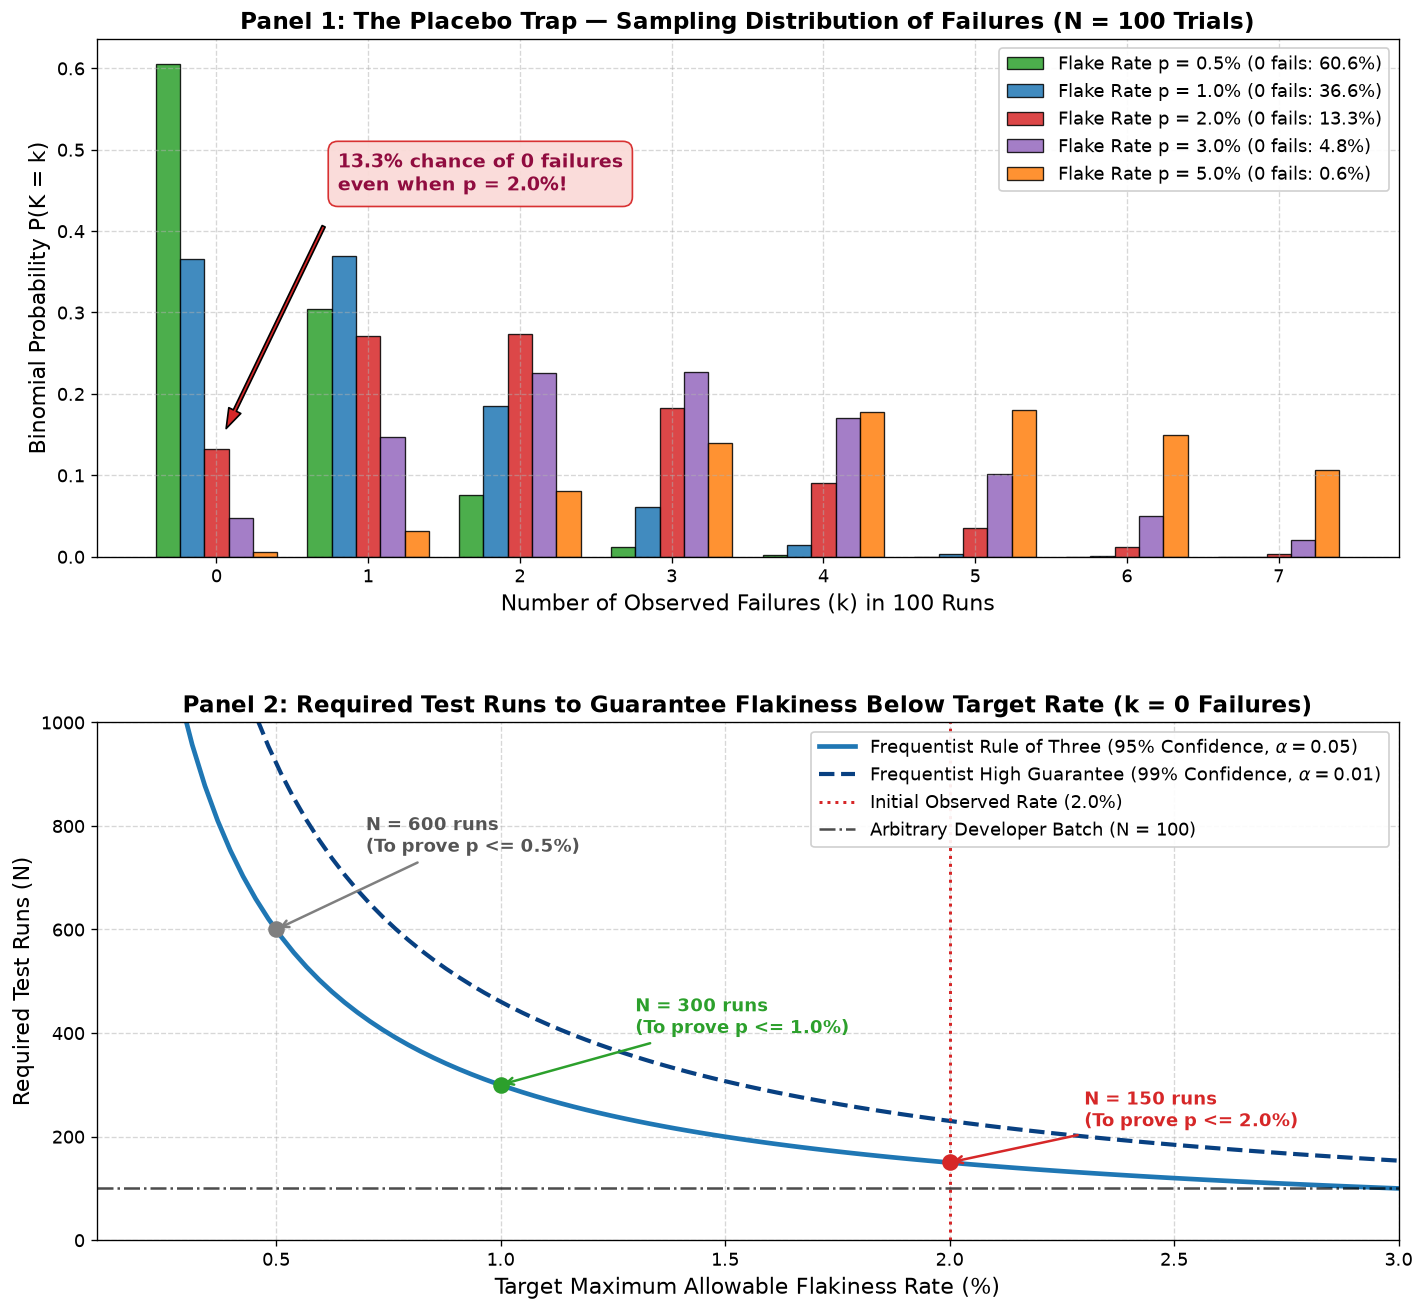

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 13), dpi=120)
fig.subplots_adjust(hspace=0.32)

# -------------------------------------------------------------
# Panel 1: Binomial Sampling Distribution for N=100 Runs
# -------------------------------------------------------------
N_trials = 100
k_vals = np.arange(0, 8)
flake_rates = [0.005, 0.01, 0.02, 0.03, 0.05]
colors = ['#2ca02c', '#1f77b4', '#d62728', '#9467bd', '#ff7f0e']

width = 0.16
for idx, (p_rate, col) in enumerate(zip(flake_rates, colors)):
    pmf = stats.binom.pmf(k_vals, N_trials, p_rate)
    offset = (idx - 2) * width
    bars = ax1.bar(k_vals + offset, pmf, width=width, color=col, alpha=0.85, 
                   edgecolor='black', linewidth=0.8,
                   label=f"Flake Rate p = {p_rate:.1%} (0 fails: {pmf[0]:.1%})")

# Highlight the 2% flake rate zero-failure bar
ax1.annotate("13.3% chance of 0 failures\neven when p = 2.0%!",
             xy=(0 + (2 - 2) * width, stats.binom.pmf(0, 100, 0.02)),
             xytext=(0.8, 0.45),
             arrowprops=dict(facecolor='#d62728', shrink=0.08, width=2, headwidth=8),
             fontsize=11.5, fontweight='bold', color='#900C3F',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#FADBD8', edgecolor='#d62728', alpha=0.95))

ax1.set_title("Panel 1: The Placebo Trap — Sampling Distribution of Failures (N = 100 Trials)", fontweight='bold')
ax1.set_xlabel("Number of Observed Failures (k) in 100 Runs")
ax1.set_ylabel("Binomial Probability P(K = k)")
ax1.set_xticks(k_vals)
ax1.set_xticklabels([str(k) for k in k_vals])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', framealpha=0.92, edgecolor='#cccccc')

# -------------------------------------------------------------
# Panel 2: Required Runs to Prove Flakiness Below Target
# -------------------------------------------------------------
target_rates = np.linspace(0.002, 0.03, 100) # 0.2% to 3%
# Frequentist Rule of Three: N >= -ln(alpha) / p_tol
N_freq_95 = -np.log(0.05) / target_rates
N_freq_99 = -np.log(0.01) / target_rates

ax2.plot(target_rates * 100, N_freq_95, color='#1f77b4', linewidth=2.8, 
         label=r"Frequentist Rule of Three (95% Confidence, $\alpha=0.05$)")
ax2.plot(target_rates * 100, N_freq_99, color='#084081', linewidth=2.5, linestyle='--',
         label=r"Frequentist High Guarantee (99% Confidence, $\alpha=0.01$)")

# Mark key points
ax2.axvline(x=2.0, color='#d62728', linestyle=':', linewidth=1.8, label="Initial Observed Rate (2.0%)")
ax2.scatter([2.0], [3.0 / 0.02], color='#d62728', s=80, zorder=5)
ax2.annotate("N = 150 runs\n(To prove p <= 2.0%)", xy=(2.0, 150), xytext=(2.3, 220),
             arrowprops=dict(arrowstyle="->", color='#d62728', lw=1.5),
             fontsize=10.5, fontweight='bold', color='#d62728')

ax2.scatter([1.0], [3.0 / 0.01], color='#2ca02c', s=80, zorder=5)
ax2.annotate("N = 300 runs\n(To prove p <= 1.0%)", xy=(1.0, 300), xytext=(1.3, 400),
             arrowprops=dict(arrowstyle="->", color='#2ca02c', lw=1.5),
             fontsize=10.5, fontweight='bold', color='#2ca02c')

ax2.scatter([0.5], [3.0 / 0.005], color='#7f7f7f', s=80, zorder=5)
ax2.annotate("N = 600 runs\n(To prove p <= 0.5%)", xy=(0.5, 600), xytext=(0.7, 750),
             arrowprops=dict(arrowstyle="->", color='#7f7f7f', lw=1.5),
             fontsize=10.5, fontweight='bold', color='#555555')

ax2.axhline(y=100, color='black', linestyle='-.', alpha=0.7, label="Arbitrary Developer Batch (N = 100)")

ax2.set_title("Panel 2: Required Test Runs to Guarantee Flakiness Below Target Rate (k = 0 Failures)", fontweight='bold')
ax2.set_xlabel("Target Maximum Allowable Flakiness Rate (%)")
ax2.set_ylabel("Required Test Runs (N)")
ax2.set_xlim(0.1, 3.0)
ax2.set_ylim(0, 1000)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', framealpha=0.92, edgecolor='#cccccc')

plt.show()

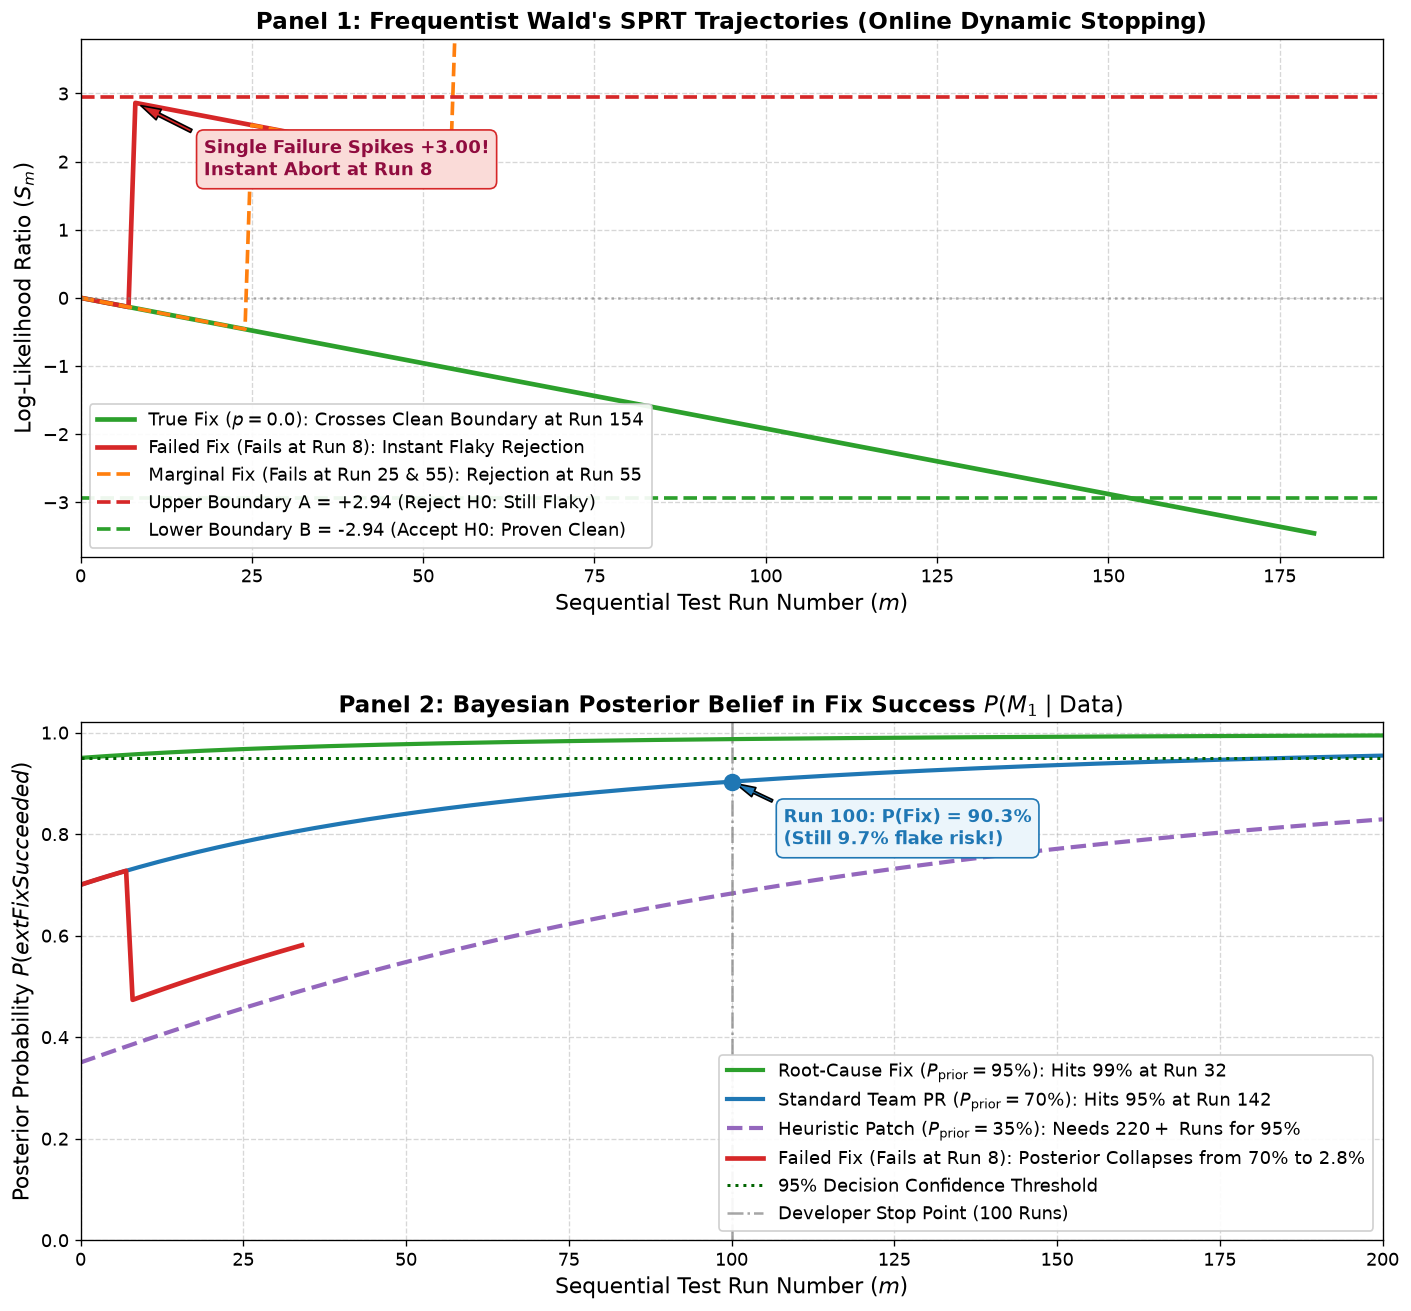

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 13), dpi=120)
fig.subplots_adjust(hspace=0.32)

# -------------------------------------------------------------
# Panel 1: Wald's SPRT Sequential Log-Likelihood Ratio Trajectory
# -------------------------------------------------------------
np.random.seed(42)
sprt_engine = SequentialProbabilityRatioTest(p0=0.001, p1=0.02, alpha=0.05, beta=0.05)

# Trajectory A: Completely fixed test (0 failures for 180 runs)
runs_A = 180
scores_A = [0.0]
cur_s = 0.0
for _ in range(runs_A):
    cur_s += sprt_engine.ll_pass
    scores_A.append(cur_s)

# Trajectory B: Ineffective fix (fails at run 8)
scores_B = [0.0]
cur_s = 0.0
for r in range(1, 40):
    if r == 8:
        cur_s += sprt_engine.ll_fail
    else:
        cur_s += sprt_engine.ll_pass
    scores_B.append(cur_s)

# Trajectory C: Slightly flaky test (fails at run 25 and 55)
scores_C = [0.0]
cur_s = 0.0
for r in range(1, 70):
    if r in [25, 55]:
        cur_s += sprt_engine.ll_fail
    else:
        cur_s += sprt_engine.ll_pass
    scores_C.append(cur_s)

x_A = np.arange(len(scores_A))
x_B = np.arange(len(scores_B))
x_C = np.arange(len(scores_C))

ax1.plot(x_A, scores_A, color='#2ca02c', linewidth=2.8, label="True Fix ($p=0.0$): Crosses Clean Boundary at Run 154")
ax1.plot(x_B, scores_B, color='#d62728', linewidth=2.8, label="Failed Fix (Fails at Run 8): Instant Flaky Rejection")
ax1.plot(x_C, scores_C, color='#ff7f0e', linewidth=2.2, linestyle='--', label="Marginal Fix (Fails at Run 25 & 55): Rejection at Run 55")

# Stopping boundaries
ax1.axhline(y=sprt_engine.A, color='#d62728', linestyle='--', linewidth=2.2, 
            label=f"Upper Boundary A = +{sprt_engine.A:.2f} (Reject H0: Still Flaky)")
ax1.axhline(y=sprt_engine.B, color='#2ca02c', linestyle='--', linewidth=2.2, 
            label=f"Lower Boundary B = {sprt_engine.B:.2f} (Accept H0: Proven Clean)")
ax1.axhline(y=0.0, color='gray', linestyle=':', alpha=0.6)

ax1.annotate("Single Failure Spikes +3.00!\nInstant Abort at Run 8",
             xy=(8, scores_B[8]), xytext=(18, 1.8),
             arrowprops=dict(facecolor='#d62728', shrink=0.08, width=2, headwidth=7),
             fontsize=11, fontweight='bold', color='#900C3F',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#FADBD8', edgecolor='#d62728'))

ax1.set_title("Panel 1: Frequentist Wald's SPRT Trajectories (Online Dynamic Stopping)", fontweight='bold')
ax1.set_xlabel("Sequential Test Run Number ($m$)")
ax1.set_ylabel("Log-Likelihood Ratio ($S_m$)")
ax1.set_xlim(0, 190)
ax1.set_ylim(-3.8, 3.8)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower left', framealpha=0.92, edgecolor='#cccccc')

# -------------------------------------------------------------
# Panel 2: Bayesian Posterior Probability P(Fix Succeeded | Runs)
# -------------------------------------------------------------
def get_bayes_trajectory(p_prior, fails_at=[]):
    p_traj = [p_prior]
    k = 0
    clean_prior = (1, 100)
    flaky_prior = (3, 99)
    for m in range(1, 201):
        if m in fails_at:
            k += 1
        log_m1 = beta_bin_lpmf(k, m, *clean_prior)
        log_m0 = beta_bin_lpmf(k, m, *flaky_prior)
        log_bf = log_m1 - log_m0
        prior_lo = np.log(p_prior / (1.0 - p_prior))
        post_p = 1.0 / (1.0 + np.exp(-(prior_lo + log_bf)))
        p_traj.append(post_p)
    return p_traj

traj_high = get_bayes_trajectory(p_prior=0.95)
traj_med  = get_bayes_trajectory(p_prior=0.70)
traj_low  = get_bayes_trajectory(p_prior=0.35)
traj_fail = get_bayes_trajectory(p_prior=0.70, fails_at=[8])

runs_range = np.arange(0, 201)
ax2.plot(runs_range, traj_high, color='#2ca02c', linewidth=2.5, 
         label=r"Root-Cause Fix ($P_{\text{prior}} = 95\%$): Hits $99\%$ at Run 32")
ax2.plot(runs_range, traj_med, color='#1f77b4', linewidth=2.5, 
         label=r"Standard Team PR ($P_{\text{prior}} = 70\%$): Hits $95\%$ at Run 142")
ax2.plot(runs_range, traj_low, color='#9467bd', linewidth=2.5, linestyle='--',
         label=r"Heuristic Patch ($P_{\text{prior}} = 35\%$): Needs $220+$ Runs for $95\%$")
ax2.plot(runs_range[:35], traj_fail[:35], color='#d62728', linewidth=2.8, 
         label=r"Failed Fix (Fails at Run 8): Posterior Collapses from $70\%$ to $2.8\%$")

ax2.axhline(y=0.95, color='darkgreen', linestyle=':', linewidth=1.8, label="95% Decision Confidence Threshold")
ax2.axvline(x=100, color='gray', linestyle='-.', alpha=0.7, label="Developer Stop Point (100 Runs)")

# Highlight Run 100 mark for standard PR
ax2.scatter([100], [traj_med[100]], color='#1f77b4', s=90, zorder=5)
ax2.annotate(f"Run 100: P(Fix) = {traj_med[100]:.1%}\n(Still 9.7% flake risk!)", 
             xy=(100, traj_med[100]), xytext=(108, 0.78),
             arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=6),
             fontsize=11, fontweight='bold', color='#1f77b4',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#EBF5FB', edgecolor='#1f77b4'))

ax2.set_title(r"Panel 2: Bayesian Posterior Belief in Fix Success $P(M_1 \mid \text{Data})$", fontweight='bold')
ax2.set_xlabel("Sequential Test Run Number ($m$)")
ax2.set_ylabel("Posterior Probability $P(\text{Fix Succeeded})$")
ax2.set_xlim(0, 200)
ax2.set_ylim(0.0, 1.02)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right', framealpha=0.92, edgecolor='#cccccc')

plt.show()

---

## 5. Bayesian Decision Theory & The Production Playbook

### 5.1 The Economics of CI Testing (Asymmetric Loss)

In professional software development, tests are not run to discover mathematical truth; tests are run to **minimize financial, operational, and organizational loss**:

* **Cost of False Peace ($C_{\text{flake}}$)**: Merging a test that is still flaky blocks the CI queue for the entire engineering organization, triggers false alarms, and creates alert fatigue.
  $$C_{\text{flake}} \approx 500\text{ USD} \quad (\text{engineering time, disrupted focus, pipeline blockage})$$
* **Cost of Extra Verification ($C_{\text{run}}$)**: Running one automated test on a cloud VM.
  $$C_{\text{run}} \approx 0.01\text{ USD} \quad (\text{GitHub Actions / EC2 runner cost})$$

After $m$ test runs with 0 failures, the expected loss of merging immediately vs. continuing to verify is:
$$\mathbb{E}[L_{\text{merge}}] = (1 - P(M_1 \mid D)) \times C_{\text{flake}} = (1 - P(M_1 \mid D)) \times 500\text{ USD}$$

* **After 50 runs** ($P(M_1) \approx 83.2\%$):
  $$\mathbb{E}[L] = (1 - 0.832) \times 500\text{ USD} = \mathbf{84.00\text{ USD}}$$
* **After 100 runs** ($P(M_1) \approx 90.3\%$):
  $$\mathbb{E}[L] = (1 - 0.903) \times 500\text{ USD} = \mathbf{48.50\text{ USD}}$$
* **After 180 runs** ($P(M_1) \approx 98.0\%$):
  $$\mathbb{E}[L] = (1 - 0.980) \times 500\text{ USD} = \mathbf{10.00\text{ USD}}$$

---

> [!WARNING]
> ### 💸 The Bad Casino Bet
> Look at the decision an engineer makes when stopping at 100 runs:
> * To run an additional 80 tests costs: $80 \times 0.01\text{ USD} = \mathbf{0.80\text{ USD}}$ of AWS compute.
> * By stopping at 100 runs, they leave an expected incident risk of: $48.50 - 10.00 = \mathbf{38.50\text{ USD}}$ on the table!
> 
> **Saving &#36;0.80 of cloud compute by taking on &#36;38.50 of expected production damage is an irrational business gamble.**
> Bayesian Decision Theory replaces the arbitrary question *"Is $p < 0.05$?"* with the business question: *"Is the cost of another test run greater than the expected reduction in outage damage?"*

---

### 5.2 Comprehensive Paradigm Comparison Matrix

| Dimension | Naive Practice ($N=100$) | Frequentist (Fisher & Rule of 3) | Frequentist SPRT (Wald) | Bayesian Bayes Factor & Decision Theory |
| :--- | :--- | :--- | :--- | :--- |
| **Meaning of 0/100** | *"It's fixed!"* (Dangerous illusion) | $p = 0.25$ (Failed to reject null; proved nothing) | Evaluates score relative to boundaries $A$ and $B$ | $BF = 4.0$ (Circumstantial clue; ~10% residual risk) |
| **Guaranteed Bound** | None | 95% upper bound is $\le 3.0\%$ (worse than original 2%!) | Strict Type I ($\alpha$) and Type II ($\beta$) error rates | Full posterior distribution $P(\theta \mid D)$ and credible intervals |
| **Stopping Rule** | Fixed $N=100$ (arbitrary) | Pre-computed: $N \ge 3 / p_{\text{tol}}$ ($300\text{--}600$ runs) | Dynamic: stops immediately when boundary is crossed | Dynamic: stops when expected loss $\mathbb{E}[L] < \text{threshold}$ |
| **Failed Fix Reaction** | Runs all 100 runs regardless | Runs all 100 runs regardless | **Aborts immediately on failure** (e.g. run 8) | **Collapses posterior immediately** to $<5\%$ on failure |
| **Considers Fix Quality?** | ❌ No | ❌ No (data must speak completely alone) | ❌ No | ✅ **Yes**: Incorporates prior engineering confidence ($P(M_1)$) |
| **Best Used For** | Quick sanity check | Regulatory audits & formal compliance | High-throughput CI gatekeeping | Continuous telemetry & cost-optimal CI routing |

---

## 6. Summary: The CI Flake Verification Playbook

When tasked with fixing and verifying flaky tests, follow these four production rules:

1. **Beware the 100-Run Illusion**: A $2\%$ flake rate has a $13.3\%$ chance of passing 100 times even if untouched. Never treat 100 passes as conclusive proof for rare events.
2. **Size Fixed Batches by the Rule of Three**: If you must run fixed batches, determine the sample size from your allowable tolerance:
   $$N \ge \frac{3}{p_{\text{target}}} \quad (N = 300 \text{ for } 1.0\%, \quad N = 600 \text{ for } 0.5\%)$$
3. **Always Implement Early-Abort in CI**: If a test fails even once during verification, cancel the workflow immediately. Do not burn expensive runner compute finishing a doomed batch.
4. **Use Stress Injection (Physics of Failure / Shaking the Table)**:

> [!TIP]
> ### 🏗️ The Hydraulic Shake Table (Physics of Failure)
> 
> In civil engineering, structural engineers do not wait 50 years for an earthquake to verify a skyscraper design. They place a physical model on a **hydraulic shake table** and vibrate it violently.
> 
> In software engineering, you should not run an idle test 600 times waiting for a 1% timing glitch:
> * **Inject Contention**: Artificially throttle CPU to 1 core, add 150ms synthetic network latency, or spin up 16 concurrent background workers.
> * **Inflate the Failure Rate**: If stress injection amplifies the baseline flake rate from **$2\% \to 30\%$**:
>   * The chance of a broken test passing 15 runs drops to $(1 - 0.30)^{15} = 0.70^{15} \approx \mathbf{0.0047} \quad (0.47\%)$!
>   * Under stress, **just 15 consecutive passes provides a Bayes Factor $> 200$ (decisive mathematical proof)** while slashing CI execution time by **$95\%$**!


## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in this
appendix. Write your solutions in the interactive attempt cells below before
expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): The Sand vs. Sledgehammer Likelihood Ratio
> **Scenario**: In an SPRT verification test, we test $H_0: p = 0.05$ (unfixed
broken test)
> versus $H_1: p = 0.001$ (successfully fixed test).
> 1. Calculate the weight of evidence (log-likelihood ratio increment) for 1
clean pass:
>    $\Delta_{\text{pass}} = \ln\left(\frac{1 - p_0}{1 - p_1}\right)$.
> 2. Calculate the weight of evidence for 1 failure:
>    $\Delta_{\text{fail}} = \ln\left(\frac{p_0}{p_1}\right)$.
> 3. How many passes does it take to cancel out the evidence of a single
failure?

In [9]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
import numpy as np

p_0 = 0.05   # broken hypothesis
p_1 = 0.001  # fixed hypothesis

# 1. Increment for pass:
# delta_pass = np.log((1 - p_0) / (1 - p_1))

# 2. Increment for failure:
# delta_fail = np.log(p_0 / p_1)

# 3. Number of passes needed to offset 1 failure:
# passes_needed = delta_fail / abs(delta_pass)

<details>
<summary><b>🔍 Click here to view the calculation</b></summary>

**Answers**:
1. $\Delta_{\text{pass}} = \ln(0.95 / 0.999) = \ln(0.95095) \approx
\mathbf{-0.0503\text{ pts}}$ (sand).
2. $\Delta_{\text{fail}} = \ln(0.05 / 0.001) = \ln(50.0) \approx
\mathbf{+3.912\text{ pts}}$ (sledgehammer).
3. Passes needed to cancel one failure: $\frac{3.912}{0.0503} \approx
\mathbf{78\text{ passes}}$!

**Insight**: A single failure completely overwhelms dozens of clean passes,
which is why sequential testing detects regressions almost instantaneously.
</details>

---

### 🟡 Tier 2 (Guided Calculation): SPRT Early-Abort Boundary Crossing
> **Scenario**: Using the probabilities from Tier 1 ($p_0 = 0.05, p_1 = 0.001$),
> we set false abort rate $\alpha = 0.05$ and false accept rate $\beta = 0.05$.
> The upper abort boundary is $B = \ln((1 - \beta)/\alpha) = \ln(0.95 / 0.05)
\approx 2.94$.
>
> A candidate test produces outcomes: `[PASS, PASS, FAIL]`. Does run 3 trigger
early abort?

In [10]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
b_threshold = np.log(19.0)  # ~2.9444

# Sequence: pass, pass, fail
# llr_run1 = delta_pass
# llr_run2 = llr_run1 + delta_pass
# llr_run3 = llr_run2 + delta_fail
# aborted = llr_run3 >= b_threshold

<details>
<summary><b>🔍 Click here to view the trace & decision</b></summary>

**Answer**: **YES, EMERGENCY ABORT TRIGGERS ON RUN 3.**

**Trace**:
- Run 1 (Pass): $\text{LLR} = -0.0503$
- Run 2 (Pass): $\text{LLR} = -0.0503 - 0.0503 = -0.1006$
- Run 3 (Fail): $\text{LLR} = -0.1006 + 3.9120 = \mathbf{+3.8114}$

Since $+3.811 > +2.944$, the test aborts immediately, saving $97$ out of $100$
runs!
</details>

---

### 🔴 Tier 3 (Production Challenge): Stress Injection Acceleration Factor
> **Scenario**: A rare concurrency race condition has baseline flake rate
$p_{\text{baseline}} = 1.0\%$.
> Under synthetic CPU contention (stress injection), its failure rate spikes to
$p_{\text{stress}} = 25.0\%$.
> 1. Under baseline, how many clean runs are required for $P(\text{0 fails}) \le
5\%$?
> 2. Under stress injection, how many clean runs are required for the same
confidence?
> 3. What is the compute acceleration factor?

In [11]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
p_base = 0.01
p_stress = 0.25
target_conf = 0.05

# Solve (1 - p)^N <= target_conf => N >= ln(target_conf) / ln(1 - p)
# n_base = ...
# n_stress = ...
# acceleration = n_base / n_stress

<details>
<summary><b>🔍 Click here to view the proof</b></summary>

**Answers**:
1. Baseline runs: $N_{\text{base}} = \frac{\ln(0.05)}{\ln(0.99)} =
\frac{-2.9957}{-0.01005} \approx \mathbf{298\text{ runs}}$.
2. Stress runs: $N_{\text{stress}} = \frac{\ln(0.05)}{\ln(0.75)} =
\frac{-2.9957}{-0.28768} \approx \mathbf{11\text{ runs}}$.
3. **Acceleration Factor**: $\frac{298}{11} \approx \mathbf{27\times\text{
faster}}$!

Stress injection compresses a 30-minute test cycle down to under 1 minute.
</details>

---


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* ➡️ **Next**: **[Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 19**: [📖 Conceptual](../conceptual/19_verifying_flaky_test_fixes.ipynb) | [🐍 Python](../python/19_verifying_flaky_test_fixes.ipynb) | [🔵 R](../r/19_verifying_flaky_test_fixes.ipynb)
